In [12]:
import numpy as np, matplotlib.pyplot as plt

fs = 40_000_000            # must match the --rate you used
center = 5.5e9             # the --frequency the dongle was tuned to

x = np.fromfile("capture.cs16", dtype=np.uint16).view(np.complex64) / 32768.0
print("DC offset:", abs(x.mean()))          # sanity check
x = x - x.mean()                             # remove DC
x = x / np.abs(x).max()                      # normalize gain

# Spectrum
n = len(x)
P = 20*np.log10(np.abs(np.fft.rfft(x*np.hanning(n)))**2 + 1e-16)
plt.figure(); plt.plot(np.fft.rfftfreq(n, 1/fs)*1e6, P)
plt.xlabel(f"MHz offset from {center/1e9:.2f} GHz"); plt.ylabel("dB"); plt.grid(True); plt.show()

# Constellation (sanity: should look like a blob at wideband noise)
plt.figure(); plt.plot(x.real, x.imag, ",", ms=0.5); plt.axis("equal"); plt.show()


DC offset: nan


/tmp/ipykernel_19574/593845899.py:6: RuntimeWarning: invalid value encountered in divide
  x = np.fromfile("capture.cs16", dtype=np.uint16).view(np.complex64) / 32768.0
/tmp/ipykernel_19574/593845899.py:9: RuntimeWarning: invalid value encountered in divide
  x = x / np.abs(x).max()                      # normalize gain


TypeError: ufunc 'rfft_n_even' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

In [16]:
x = np.fromfile("capture.cs16", dtype=np.uint16) / 32768.0
x.mean()

np.float64(0.9530320338668823)

In [ ]:
import numpy as np, matplotlib.pyplot as plt

# --- must match your capture command ---
fs     = 40_000_000   # the --rate used (default is 40 MS/s)
center = 2.437e9      # the --frequency used (default, channel 6)

# 1) Read as SIGNED 16-bit (fixing the uint16 bug)
raw = np.fromfile("capture.cs16", dtype=np.int16)
print("bytes:", raw.size * 2, " raw sample count:", raw.size)
print("file ends with odd byte?" , (raw.size % 2 != 0))

# 2) Keep only full I/Q pairs — discards the stray byte that made a NaN
n_pairs = raw.size // 2
x = (raw[:2 * n_pairs].astype(np.float32)).view(np.complex64)   # explicit float step: no int overflow
print("complex samples:", x.size)

# 3) Verify before computing anything
print("contains NaN/Inf:", not np.isfinite(x).all())
print("range:", x[np.isfinite(x)].real.min(), "…", x[np.isfinite(x)].real.max())

# (if there were NaNs, drop just those:  x = x[np.isfinite(x)])

# 4) DC offset & normalization
dc = float(np.abs(x.mean()))
print("DC offset:", dc)
x = x - x.mean()
scale = float(np.abs(x).max())
if scale > 0 and np.isfinite(scale):
    x = x / scale       # normalize gain

# 5) Spectrum — with an even-length guard as extra insurance
n = len(x) & ~1         # force even: rfft wants an even sample count for the hanning window
P = 20*np.log10(np.abs(np.fft.rfft(x * np.hanning(n).astype(np.float32)))**2 + 1e-16)
plt.figure(); plt.plot(np.fft.rfftfreq(n, 1/fs) * 1e6, P)
plt.xlabel(f"MHz offset from {center/1e9:.3f} GHz"); plt.ylabel("dB"); plt.grid(True); plt.show()

# 6) Constellation
plt.figure(); plt.plot(x.real[:: 32], x.imag[:: 32], ",", ms=0.5)
plt.axis("equal"); plt.xlabel("I"); plt.ylabel("Q"); plt.show()

# 7) Time-domain peek (first 500 µs: is the trace alive, or pure noise?)
plt.figure(); plt.plot(x.real[:20000], lw=0.3)
plt.xlabel(f"sample (out of {x.size})"); plt.show()


bytes: 339992576  raw sample count: 169996288
file ends with odd byte? False
complex samples: 84998144
contains NaN/Inf: False
range: -8188.0 … 8188.0
DC offset: 4.034265995025635


TypeError: ufunc 'rfft_n_even' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

DC offset: 0.28242430090904236


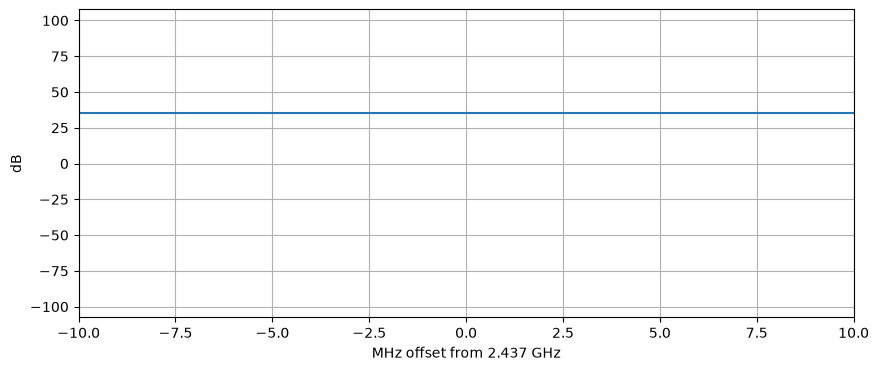

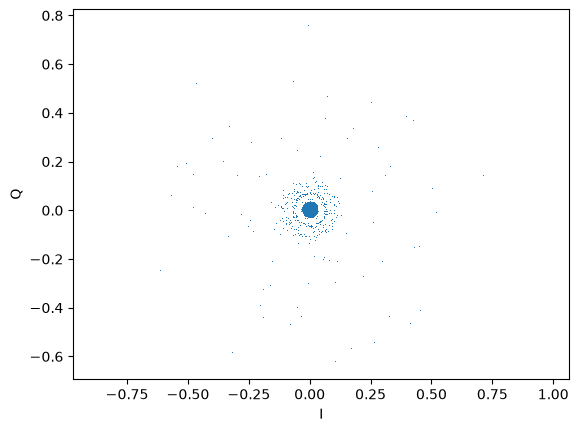

In [ ]:
# --- I/Q load (unchanged, working) ---
raw     = np.fromfile("capture.cs16", dtype=np.int16)
n_pairs = raw.size // 2
x = (raw[:2 * n_pairs].astype(np.float32)).view(np.complex64)

# --- DC offset & normalize ---
dc = float(np.abs(x.mean()))
print("DC offset:", dc)
x = x - x.mean()
scale = float(np.abs(x).max())
if scale > 0 and np.isfinite(scale):
    x = x / scale

# --- Spectrum: complex FFT of the I/Q signal ---
n = len(x)
w = np.hanning(n).astype(np.float32)
X  = np.fft.fft(x * w)                            # FFT of the complex channel
Xs = np.fft.fftshift(X)                           # center 0 Hz in the middle
f  = np.fft.fftshift(np.fft.fftfreq(n, 1/fs)) * 1e6   # MHz, −fs/2…+fs/2
P  = 20 * np.log10(np.abs(Xs) ** 2 + 1e-16)

plt.figure(figsize=(10, 4))
plt.plot(f, P)
plt.xlabel(f"MHz offset from {center/1e9:.3f} GHz")
plt.ylabel("dB"); plt.grid(True)
plt.xlim(-10, 10)           # ±10 MHz window out of the ±20 MHz total
plt.show()

# --- Constellation ---
plt.figure()
plt.plot(x.real[::32], x.imag[::32], ",", ms=0.5)
plt.axis("equal"); plt.xlabel("I"); plt.ylabel("Q"); plt.show()


bytes: 339992576  raw sample count: 169996288
file ends with odd byte? False
complex samples: 84998144
contains NaN/Inf: False
range: -8188.0 … 8188.0
DC offset: 4.034265995025635


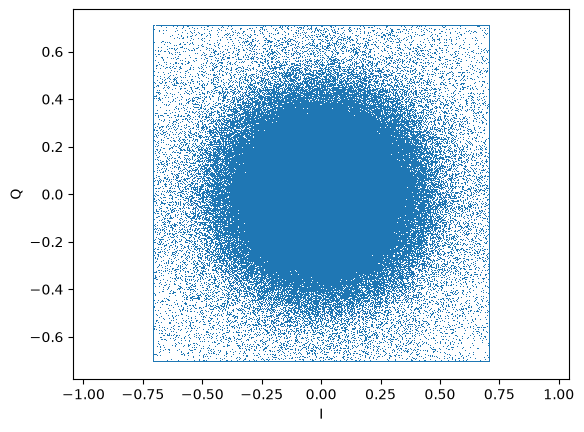

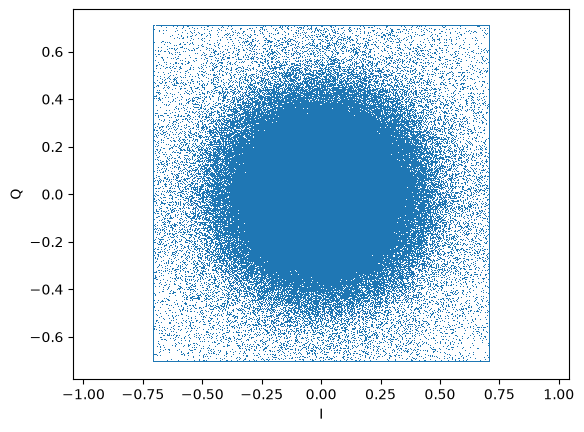

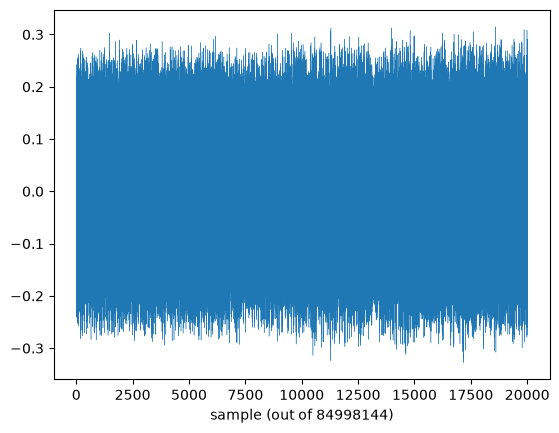

In [3]:
import numpy as np, matplotlib.pyplot as plt

# --- must match your capture command ---
fs     = 40_000_000   # the --rate used (default is 40 MS/s)
center = 2.437e9      # the --frequency used (default, channel 6)

# 1) Read as SIGNED 16-bit (fixing the uint16 bug)
raw = np.fromfile("capture2.cs16", dtype=np.int16)
print("bytes:", raw.size * 2, " raw sample count:", raw.size)
print("file ends with odd byte?" , (raw.size % 2 != 0))

# 2) Keep only full I/Q pairs — discards the stray byte that made a NaN
n_pairs = raw.size // 2
x = (raw[:2 * n_pairs].astype(np.float32)).view(np.complex64)   # explicit float step: no int overflow
print("complex samples:", x.size)

# 3) Verify before computing anything
print("contains NaN/Inf:", not np.isfinite(x).all())
print("range:", x[np.isfinite(x)].real.min(), "…", x[np.isfinite(x)].real.max())

# (if there were NaNs, drop just those:  x = x[np.isfinite(x)])

# 4) DC offset & normalization
dc = float(np.abs(x.mean()))
print("DC offset:", dc)
x = x - x.mean()
scale = float(np.abs(x).max())
if scale > 0 and np.isfinite(scale):
    x = x / scale       # normalize gain

# 5) Spectrum — with an even-length guard as extra insurance


# --- Constellation ---
plt.figure()
plt.plot(x.real[::32], x.imag[::32], ",", ms=0.5)
plt.axis("equal"); plt.xlabel("I"); plt.ylabel("Q"); plt.show()

# 6) Constellation
plt.figure(); plt.plot(x.real[:: 32], x.imag[:: 32], ",", ms=0.5)
plt.axis("equal"); plt.xlabel("I"); plt.ylabel("Q"); plt.show()

# 7) Time-domain peek (first 500 µs: is the trace alive, or pure noise?)
plt.figure(); plt.plot(x.real[:20000], lw=0.3)
plt.xlabel(f"sample (out of {x.size})"); plt.show()


DC offset: 4.034265995025635


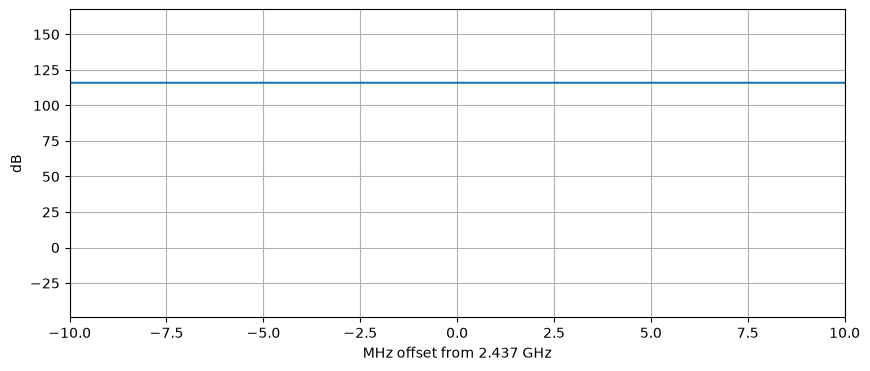

In [5]:
# --- I/Q load (unchanged, working) ---
raw     = np.fromfile("capture2.cs16", dtype=np.int16)
n_pairs = raw.size // 2
x = (raw[:2 * n_pairs].astype(np.float32)).view(np.complex64)

# --- DC offset & normalize ---
dc = float(np.abs(x.mean()))
print("DC offset:", dc)
x = x - x.mean()
scale = float(np.abs(x).max())
if scale > 0 and np.isfinite(scale):
    x = x / scale

# --- Spectrum: complex FFT of the I/Q signal ---
n = len(x)
w = np.hanning(n).astype(np.float32)
X  = np.fft.fft(x * w)                            # FFT of the complex channel
Xs = np.fft.fftshift(X)                           # center 0 Hz in the middle
f  = np.fft.fftshift(np.fft.fftfreq(n, 1/fs)) * 1e6   # MHz, −fs/2…+fs/2
P  = 20 * np.log10(np.abs(Xs) ** 2 + 1e-16)

plt.figure(figsize=(10, 4))
plt.plot(f, P)
plt.xlabel(f"MHz offset from {center/1e9:.3f} GHz")
plt.ylabel("dB"); plt.grid(True)
plt.xlim(-10, 10)           # ±10 MHz window out of the ±20 MHz total
plt.show()

P min/max/mean (dB): -39.360687 157.62965 110.18427


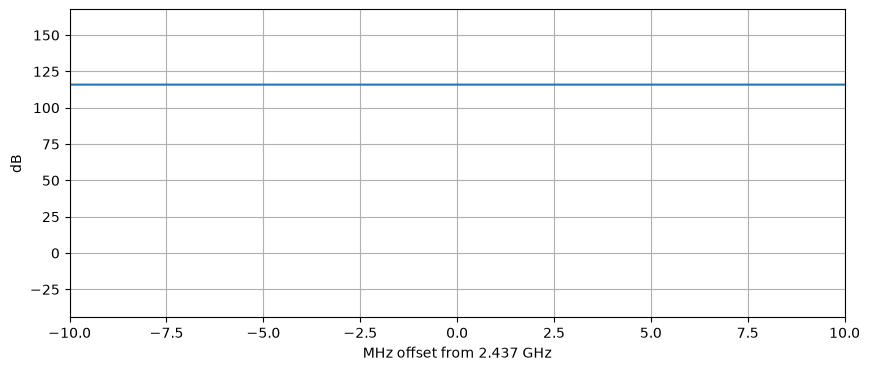

In [6]:
print("P min/max/mean (dB):", P.min(), P.max(), P.mean())

plt.figure(figsize=(10, 4))
plt.plot(f, P)
plt.ylim(P.min() - 5, P.max() + 10)   # zoom the y-axis — autoscale squashes ±3 dB
plt.xlabel(f"MHz offset from {center/1e9:.3f} GHz"); plt.ylabel("dB"); plt.grid(True)
plt.xlim(-10, 10)
plt.show()

In [10]:
import numpy as np
np.fromfile("wifi_channel_1.cs16", dtype=np.int16).astype(np.float32).tofile("wifi_channel_1.c32")

averaged over 1524 windows


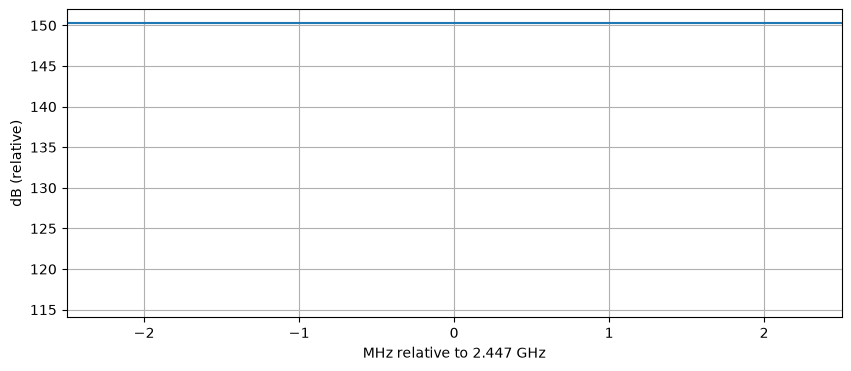

In [9]:
import numpy as np, matplotlib.pyplot as plt

fs, center = 10_000_000, 2.447e9     # must match your --rate / --frequency
seg = 65536                          # 655 µs window at 10 MSps

raw = np.fromfile("wifi.cs16", dtype=np.int16)
n_pairs = raw.size // 2
x = (raw[:2*n_pairs].astype(np.float32)).view(np.complex64)
x = x - x.mean()

w   = np.hanning(seg).astype(np.float32)
hop = seg // 2
P   = np.zeros(seg, dtype=np.float32)   # fft of complex length seg → seg bins
n_avg = 0
for s in range(0, x.size - seg + 1, hop):
    P += np.abs(np.fft.fft(x[s:s+seg] * w))**2     # ← fft, not rfft
    n_avg += 1
print("averaged over", n_avg, "windows")

# fft returns bins in 0…fs/2, then −fs/2…0 — fftshift centers them for plotting
P = np.fft.fftshift(P)
f = np.fft.fftshift(np.fft.fftfreq(seg, 1/fs)) * 1e6

plt.figure(figsize=(10, 4))
plt.plot(f, 10*np.log10(P + 1e-12))
plt.xlim(-2.5, 2.5)
plt.xlabel(f"MHz relative to {center/1e9:.3f} GHz"); plt.ylabel("dB (relative)"); plt.grid(True)
plt.show()
